In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.tree import DecisionTreeClassifier
from sklearn.naive_bayes import GaussianNB

file_path = "BookMyShow_Dataset.xlsx"

movies = pd.read_excel(file_path, sheet_name="Movies")
reviews = pd.read_excel(file_path, sheet_name="Reviews")

print("Movies:")
display(movies.head())

print("Reviews:")
display(reviews.head())

Movies:


,movie_id,title,genre,language,duration,rating,release_date,description
0,MV_1,Address clear,Sci-Fi,Kannada,118,6.6,2022-03-05,Leave research put serious. Stand wrong player...
1,MV_2,Popular business,Comedy,Kannada,122,4.2,2022-03-28,Stuff next list crime his.\nTurn one wish move...
2,MV_3,Determine amount art,Sci-Fi,Bengali,130,5.1,2018-09-09,Goal study up world treatment. Night idea catc...
3,MV_4,East,Thriller,Malayalam,98,5.3,2009-07-12,Morning run card work cover. Much party indust...
4,MV_5,Ready road establish,Romance,Kannada,171,8.8,2010-01-12,Agency five by light person care. Sea else fro...


Reviews:


,review_id,user_id,movie_id,rating,review_text,review_date
0,REV_1,US_8392,MV_8805,1.2,Could be better.,2025-07-01 16:16:00
1,REV_2,US_9928,MV_1331,3.7,Could be better.,2024-10-30 15:30:27
2,REV_3,US_4495,MV_3210,2.2,Could be better.,2024-03-08 04:10:25
3,REV_4,US_1868,MV_2311,6.3,Great movie!,2024-05-13 10:00:49
4,REV_5,US_8470,MV_8712,5.2,Could be better.,2024-09-14 19:58:28


In [ ]:
movies = movies.rename(columns={"rating": "movie_rating"})
reviews = reviews.rename(columns={"rating": "review_rating"})

df = pd.merge(movies, reviews, on="movie_id", how="inner")

df["High_Rating"] = (df["review_rating"] >= 4).astype(int)

X = df[["movie_rating", "duration"]]
y = df["High_Rating"]

X = X.dropna()
y = y.loc[X.index]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("\nClass distribution:")
print(y.value_counts())

Training samples: 8000
Testing samples: 2000

Class distribution:
High_Rating
1    6649
0    3351
Name: count, dtype: int64


In [ ]:
dt_gini = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

dt_gini.fit(X_train_scaled, y_train)

y_pred_dt = dt_gini.predict(X_test_scaled)

print("Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree Accuracy: 0.6615

Classification Report:
              precision    recall  f1-score   support

           0       0.40      0.01      0.03       672
           1       0.66      0.99      0.80      1328

    accuracy                           0.66      2000
   macro avg       0.53      0.50      0.41      2000
weighted avg       0.58      0.66      0.54      2000


Confusion Matrix:
[[  10  662]
 [  15 1313]]


In [ ]:
def custom_decision_tree(X_train, y_train, X_test):
    model = DecisionTreeClassifier(
        criterion="entropy",
        max_depth=5,
        random_state=42
    )

    model.fit(X_train, y_train)
    return model.predict(X_test)

y_pred_custom_dt = custom_decision_tree(
    X_train_scaled,
    y_train,
    X_test_scaled
)

print("Custom Decision Tree Accuracy:",
      accuracy_score(y_test, y_pred_custom_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_custom_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_custom_dt))

Custom Decision Tree Accuracy: 0.6615

Classification Report:
              precision    recall  f1-score   support

           0       0.40      0.01      0.03       672
           1       0.66      0.99      0.80      1328

    accuracy                           0.66      2000
   macro avg       0.53      0.50      0.41      2000
weighted avg       0.58      0.66      0.54      2000


Confusion Matrix:
[[  10  662]
 [  15 1313]]


In [ ]:
nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

y_pred_nb = nb_model.predict(X_test_scaled)

print("Naive Bayes Accuracy:",
      accuracy_score(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

Naive Bayes Accuracy: 0.664

Classification Report:
              precision    recall  f1-score   support

           0       0.00      0.00      0.00       672
           1       0.66      1.00      0.80      1328

    accuracy                           0.66      2000
   macro avg       0.33      0.50      0.40      2000
weighted avg       0.44      0.66      0.53      2000


Confusion Matrix:
[[   0  672]
 [   0 1328]]


/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))
/usr/local/lib/python3.13/dist-packages/sklearn/metrics/_classification.py:1565: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", len(result))


In [ ]:
print("Training class distribution:")
print(y_train.value_counts())

print("\nTest class distribution:")
print(y_test.value_counts())

print("\nFeature statistics by class:")
print(df.groupby("High_Rating")[["movie_rating", "duration"]].mean())

print("\nNaive Bayes predicted distribution:")
print(pd.Series(y_pred_nb).value_counts())

Training class distribution:
High_Rating
1    5321
0    2679
Name: count, dtype: int64

Test class distribution:
High_Rating
1    1328
0     672
Name: count, dtype: int64

Feature statistics by class:
             movie_rating    duration
High_Rating                          
0                5.993644  135.777678
1                6.018830  135.853813

Naive Bayes predicted distribution:
1    2000
Name: count, dtype: int64


In [ ]:
print(df[["movie_rating", "duration", "High_Rating"]].describe())

print("\nCorrelation:")
print(df[["movie_rating", "duration", "High_Rating"]].corr())

       movie_rating      duration   High_Rating
count  10000.000000  10000.000000  10000.000000
mean       6.010390    135.828300      0.664900
std        1.735865     26.518242      0.472049
min        3.000000     90.000000      0.000000
25%        4.500000    113.000000      0.000000
50%        6.000000    137.000000      1.000000
75%        7.500000    159.000000      1.000000
max        9.000000    180.000000      1.000000

Correlation:
              movie_rating  duration  High_Rating
movie_rating      1.000000  0.001700     0.006849
duration          0.001700  1.000000     0.001355
High_Rating       0.006849  0.001355     1.000000


In [ ]:
import pandas as pd
import numpy as np

from google.colab import files

uploaded = files.upload()

file_name = list(uploaded.keys())[0]

users = pd.read_excel(file_name, sheet_name="Users")
movies = pd.read_excel(file_name, sheet_name="Movies")
theaters = pd.read_excel(file_name, sheet_name="Theaters")
screens = pd.read_excel(file_name, sheet_name="Screens")
shows = pd.read_excel(file_name, sheet_name="Shows")
bookings = pd.read_excel(file_name, sheet_name="Bookings")
seats = pd.read_excel(file_name, sheet_name="Seats")
payments = pd.read_excel(file_name, sheet_name="Payments")
reviews = pd.read_excel(file_name, sheet_name="Reviews")

tables = {
    "Users": users,
    "Movies": movies,
    "Theaters": theaters,
    "Screens": screens,
    "Shows": shows,
    "Bookings": bookings,
    "Seats": seats,
    "Payments": payments,
    "Reviews": reviews
}

for name, table in tables.items():
    print(name, ":", table.shape)

Saving BookMyShow_Dataset.xlsx to BookMyShow_Dataset (1).xlsx
Users : (10000, 5)
Movies : (10000, 8)
Theaters : (10000, 5)
Screens : (1000, 4)
Shows : (10000, 8)
Bookings : (10000, 6)
Seats : (10000, 7)
Payments : (10000, 6)
Reviews : (10000, 6)


In [ ]:
movies_model = movies.rename(columns={
    "rating": "movie_rating"
})
show_summary = shows.groupby("movie_id").agg(
    avg_ticket_price=("price_per_ticket", "mean"),
    avg_available_seats=("available_seats", "mean"),
    show_count=("show_id", "count")
).reset_index()
df = (
    reviews
    .merge(movies_model, on="movie_id", how="inner")
    .merge(show_summary, on="movie_id", how="left")
    .merge(
        users[["user_id", "date_of_birth"]],
        on="user_id",
        how="inner"
    )
)
df["user_age"] = (
    (df["review_date"] - df["date_of_birth"]).dt.days / 365.25
)
df["High_Rating"] = (df["rating"] >= 5.5).astype(int)
features = [
    "movie_rating",
    "duration",
    "avg_ticket_price",
    "avg_available_seats",
    "show_count",
    "user_age",
    "genre",
    "language"
]
df = df.dropna(
    subset=features + ["High_Rating"]
)
X = pd.get_dummies(
    df[features],
    columns=["genre", "language"],
    drop_first=True
)
y = df["High_Rating"]
print("Classification Dataset Shape:", df.shape)
print("\nClass Distribution:")
print(y.value_counts())
print("\nFeature Columns:")
print(X.columns.tolist())

Classification Dataset Shape: (6350, 19)

Class Distribution:
High_Rating
0    3207
1    3143
Name: count, dtype: int64

Feature Columns:
['movie_rating', 'duration', 'avg_ticket_price', 'avg_available_seats', 'show_count', 'user_age', 'genre_Comedy', 'genre_Drama', 'genre_Horror', 'genre_Romance', 'genre_Sci-Fi', 'genre_Thriller', 'language_English', 'language_Hindi', 'language_Kannada', 'language_Malayalam', 'language_Tamil', 'language_Telugu']


In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])

print("\nTraining Class Distribution:")
print(y_train.value_counts())

print("\nTesting Class Distribution:")
print(y_test.value_counts())

Training Samples: 5080
Testing Samples: 1270

Training Class Distribution:
High_Rating
0    2566
1    2514
Name: count, dtype: int64

Testing Class Distribution:
High_Rating
0    641
1    629
Name: count, dtype: int64


In [ ]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

dt_gini = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

dt_gini.fit(X_train_scaled, y_train)

y_pred_dt = dt_gini.predict(X_test_scaled)

print("Decision Tree Accuracy:")
print(accuracy_score(y_test, y_pred_dt))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_dt))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_dt))

Decision Tree Accuracy:
0.5070866141732283

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.81      0.63       641
           1       0.51      0.19      0.28       629

    accuracy                           0.51      1270
   macro avg       0.51      0.50      0.45      1270
weighted avg       0.51      0.51      0.45      1270


Confusion Matrix:
[[522 119]
 [507 122]]


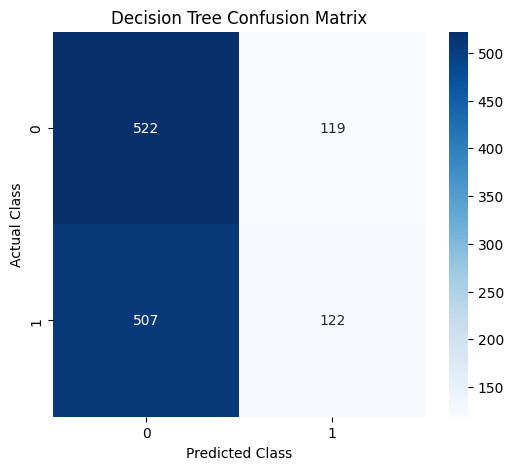

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm_dt = confusion_matrix(y_test, y_pred_dt)

plt.figure(figsize=(6, 5))
sns.heatmap(
    cm_dt,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["0", "1"],
    yticklabels=["0", "1"]
)

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Decision Tree Confusion Matrix")
plt.show()

In [ ]:
def custom_decision_tree(X_train, y_train, X_test):
    model = DecisionTreeClassifier(
        criterion="entropy",
        max_depth=5,
        random_state=42
    )

    model.fit(X_train, y_train)

    return model, model.predict(X_test)


dt_entropy, y_pred_entropy = custom_decision_tree(
    X_train_scaled,
    y_train,
    X_test_scaled
)

print("Custom Decision Tree Accuracy:")
print(accuracy_score(y_test, y_pred_entropy))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_entropy))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_entropy))

Custom Decision Tree Accuracy:
0.5078740157480315

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.78      0.61       641
           1       0.51      0.23      0.32       629

    accuracy                           0.51      1270
   macro avg       0.51      0.51      0.47      1270
weighted avg       0.51      0.51      0.47      1270


Confusion Matrix:
[[499 142]
 [483 146]]


In [ ]:
from sklearn.naive_bayes import GaussianNB

nb_model = GaussianNB()

nb_model.fit(X_train_scaled, y_train)

y_pred_nb = nb_model.predict(X_test_scaled)

print("Naive Bayes Accuracy:")
print(accuracy_score(y_test, y_pred_nb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_nb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_nb))

Naive Bayes Accuracy:
0.5039370078740157

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.54      0.52       641
           1       0.50      0.46      0.48       629

    accuracy                           0.50      1270
   macro avg       0.50      0.50      0.50      1270
weighted avg       0.50      0.50      0.50      1270


Confusion Matrix:
[[348 293]
 [337 292]]


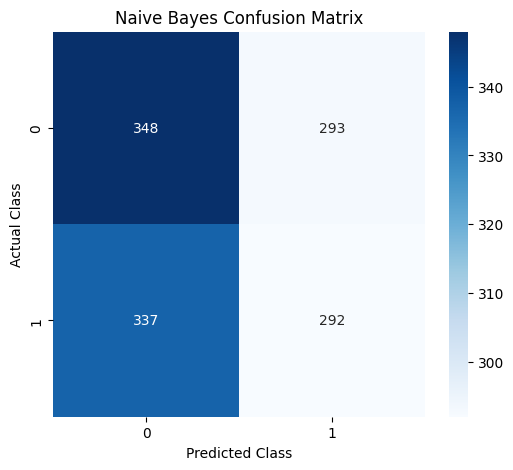

In [ ]:
cm_nb = confusion_matrix(y_test, y_pred_nb)

plt.figure(figsize=(6, 5))
sns.heatmap(cm_nb, annot=True, fmt="d", cmap="Blues",
            xticklabels=["0", "1"],
            yticklabels=["0", "1"])

plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.title("Naive Bayes Confusion Matrix")
plt.show()

In [ ]:
def custom_naive_bayes(X_train, y_train, X_test):
    model = GaussianNB()

    model.fit(X_train, y_train)

    return model, model.predict(X_test)


custom_nb, y_pred_custom_nb = custom_naive_bayes(
    X_train_scaled,
    y_train,
    X_test_scaled
)

print("Custom Naive Bayes Accuracy:")
print(accuracy_score(y_test, y_pred_custom_nb))

print("\nClassification Report:")
print(classification_report(y_test, y_pred_custom_nb))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred_custom_nb))

Custom Naive Bayes Accuracy:
0.5039370078740157

Classification Report:
              precision    recall  f1-score   support

           0       0.51      0.54      0.52       641
           1       0.50      0.46      0.48       629

    accuracy                           0.50      1270
   macro avg       0.50      0.50      0.50      1270
weighted avg       0.50      0.50      0.50      1270


Confusion Matrix:
[[348 293]
 [337 292]]


In [ ]:
results = pd.DataFrame({
    "Model": [
        "Decision Tree - Gini",
        "Decision Tree - Entropy",
        "Naive Bayes",
        "Custom Naive Bayes"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_entropy),
        accuracy_score(y_test, y_pred_nb),
        accuracy_score(y_test, y_pred_custom_nb)
    ]
})

print(results)

                     Model  Accuracy
0     Decision Tree - Gini  0.507087
1  Decision Tree - Entropy  0.507874
2              Naive Bayes  0.503937
3       Custom Naive Bayes  0.503937
